# 🎮 Exploratory Data Analysis (EDA) — Global Video Game Market

## 📌 1. Introduction and Objectives
This notebook performs an exploratory data analysis on the historical video game sales dataset from Kaggle (`dato.csv`).

All data cleaning and feature engineering are delegated to `run_pipeline()` from `pipeline.py`, which serves as the single source of processing shared with the dashboard (`app.py`) and the unit tests (`test_pipeline.py`).

The primary objective is to understand the core factors driving commercial success across different global regions and to provide data-driven recommendations for executive decision-making.

### ❓ Research Questions
1. **Univariate Analysis:** Which platforms and genres lead historical commercial sales volume?
2. **Bivariate Analysis (Western Market):** Is there a strong linear correlation between North American (`NA_Sales`) and European (`EU_Sales`) market performance?
3. **Regional Behavior:** How does the Japanese market (`JP_Sales`) differ from Western consumption patterns?
4. **Outliers & Distribution:** How do blockbuster titles skew the overall market average?
5. **Efficiency & Production:** How much memory do type downcasting and categorical encoding save in the processed dataset?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load raw dataset
df_raw = pd.read_csv("dato.csv")

# Capture exact row count and initial memory consumption
initial_rows = len(df_raw)
initial_memory_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Total loaded records: {initial_rows}")
print(f"Initial memory usage: {initial_memory_mb:.2f} MB")
df_raw.head()

Total loaded records: 7112
Initial memory usage: 0.87 MB


,Platform,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Rating,Critic_Score_Class
0,Wii,Sports,Nintendo,"41,36","28,96","3,77","8,45","82,54",E,Bueno
1,Wii,Racing,Nintendo,"15,68","12,8","3,79","3,29","35,57",E,Excelente
2,Wii,Sports,Nintendo,"15,61","10,95","3,28","2,95","32,78",E,Excelente
3,DS,Platform,Nintendo,"11,28","9,15","6,5","2,88","29,81",E,Excelente
4,Wii,Misc,Nintendo,"13,96","9,18","2,93","2,84","28,92",E,Malo


In [2]:
from pipeline import run_pipeline

# Single source of processing: missing-value handling, duplicate removal,
# type conversion and feature engineering all happen inside pipeline.py
df_clean = run_pipeline("dato.csv", "dato_cleaned.csv")

print(f"DataFrame 'df_clean' generated by run_pipeline(). Records: {len(df_clean)}")
df_clean.head()

DataFrame 'df_clean' generated by run_pipeline(). Records: 7088


,Platform,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Rating,Critic_Score_Class,NA_EU_Share,Sales_Category
0,Wii,Sports,Nintendo,41.360001,28.959999,3.77,8.45,82.540001,E,Bueno,0.851951,Blockbuster (>2M)
1,Wii,Racing,Nintendo,15.680000,12.800000,3.79,3.29,35.570000,E,Excelente,0.800675,Blockbuster (>2M)
2,Wii,Sports,Nintendo,15.610000,10.950000,3.28,2.95,32.779999,E,Excelente,0.810250,Blockbuster (>2M)
3,DS,Platform,Nintendo,11.280000,9.150000,6.50,2.88,29.809999,E,Excelente,0.685341,Blockbuster (>2M)
4,Wii,Misc,Nintendo,13.960000,9.180000,2.93,2.84,28.920000,E,Malo,0.800138,Blockbuster (>2M)


## 2. Data Loading & Pipeline Integration

### 🔎 Interpretation: Data Loading & Pipeline Processing
* **What we are observing:** The raw dataset (`dato.csv`) loaded for baseline measurement, and the analysis-ready DataFrame returned by `run_pipeline()`.
* **What result we found:** The raw file contains **7,112 records**. The pipeline removed **24 duplicate records**, yielding **7,088 analysis-ready rows** with **0 missing values**. The current dataset contains no null `Publisher` entries, so that filter acts as a defensive safeguard.
* **Business & Technical Meaning:** Cleaning and feature engineering now come from one source (`pipeline.py`) — the same code validated by `test_pipeline.py` and consumed by `app.py` — eliminating duplicated logic and guaranteeing consistency between notebook, dashboard, and tests.

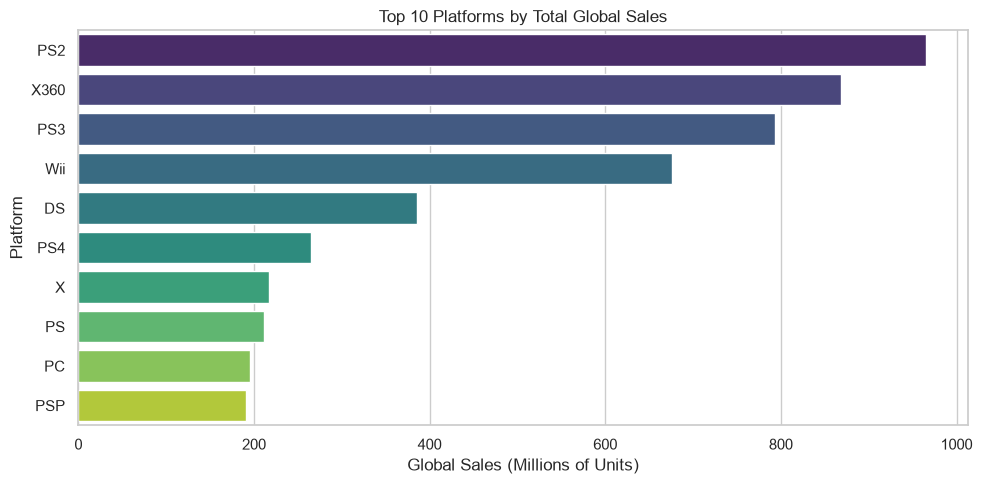

In [3]:
platform_sales = (
    df_clean.groupby('Platform', observed=True)['Global_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=platform_sales.values,
    y=platform_sales.index.astype(str),
    hue=platform_sales.index.astype(str),
    palette='viridis',
    legend=False,
)
plt.title('Top 10 Platforms by Total Global Sales')
plt.xlabel('Global Sales (Millions of Units)')
plt.ylabel('Platform')
plt.tight_layout()
plt.show()

## 3. Univariate Analysis

### 🔎 Interpretation: Top Platforms
* **What we are observing:** Total global sales volume distributed across the top 10 historical gaming platforms.
* **What result we found:** Legacy home consoles (PS2, X360, PS3, Wii) dominate cumulative historical sales.
* **Business & Technical Meaning:** Market volume is heavily concentrated in a select few dominant platform ecosystems.

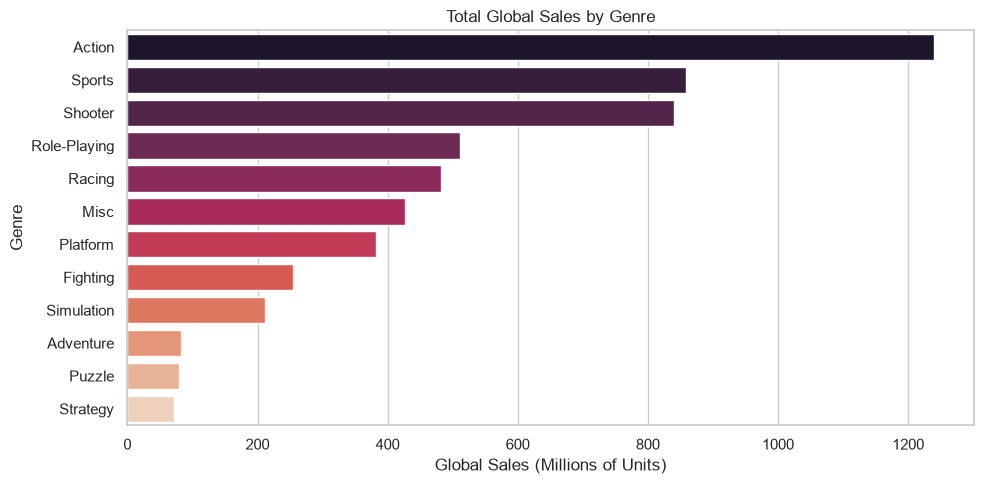

In [4]:
# Aggregate global sales by genre
genre_sales = (
    df_clean.groupby('Genre', observed=True)['Global_Sales']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=genre_sales.values,
    y=genre_sales.index.astype(str),
    hue=genre_sales.index.astype(str),
    palette='rocket',
    legend=False
)
plt.title('Total Global Sales by Genre')
plt.xlabel('Global Sales (Millions of Units)')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

### 🔎 Interpretation: Top Genres
* **What we are observing:** Global sales breakdown across all video game genres.
* **What result we found:** Action, Sports, and Shooter genres account for the highest total volume globally.
* **Business & Technical Meaning:** Mass-market appeal is centered around action and competitive gameplay genres.

In [5]:
# Quality checkpoint on the pipeline output (no manual re-cleaning).
# Memory is compared in-memory: reloading dato_cleaned.csv from disk would
# lose the optimized dtypes (categories / float32) and inflate the figure.
raw_memory_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
clean_memory_mb = df_clean.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Original records: {initial_rows}")
print(f"Cleaned records: {len(df_clean)}")
print(f"Remaining duplicates: {df_clean.duplicated().sum()}")
print(f"Missing values: {df_clean.isnull().sum().sum()}")
print(f"Original memory: {raw_memory_mb:.2f} MB")
print(f"Optimized memory: {clean_memory_mb:.2f} MB")
print(f"Memory reduction: {(raw_memory_mb - clean_memory_mb) / raw_memory_mb * 100:.1f}%")

df_clean.dtypes

Original records: 7112
Cleaned records: 7088
Remaining duplicates: 0
Missing values: 0
Original memory: 0.87 MB
Optimized memory: 0.42 MB
Memory reduction: 51.5%


Platform              category
Genre                 category
Publisher             category
NA_Sales               float32
EU_Sales               float32
JP_Sales               float32
Other_Sales            float32
Global_Sales           float32
Rating                     str
Critic_Score_Class         str
NA_EU_Share            float32
Sales_Category        category
dtype: object

## 4. Data Quality & Memory Optimization

### 🔎 Interpretation: Data Quality & Optimization
* **What we are observing:** Record counts, duplicates, missing values, and the in-memory footprint of the raw vs. pipeline-processed DataFrame.
* **What result we found:** The pipeline output has **0 duplicates and 0 missing values**. Type downcasting (`float32` sales columns) and categorical encoding of `Platform`/`Genre`/`Publisher` reduce memory usage from **0.87 MB to 0.42 MB (≈ 52% reduction)**.
* **Business & Technical Meaning:** Dropping duplicate records prevents double-counted sales in publisher-level analyses, while the optimized dtypes keep the processing pipeline lightweight. Note: these figures correspond to the in-memory DataFrame returned by the pipeline; reading `dato_cleaned.csv` back from disk loses the optimized dtypes and inflates apparent memory usage.

In [6]:
# NA_EU_Share and Sales_Category are generated by engineer_features()
# inside pipeline.py — only inspected here, never recomputed.
print("Sales Category Breakdown:")
print(df_clean['Sales_Category'].value_counts())

df_clean[['NA_EU_Share', 'Sales_Category']].head()

Sales Category Breakdown:
Sales_Category
Moderate (0.1M-0.5M)    3029
Major (0.5M-2M)         1905
Niche (<0.1M)           1572
Blockbuster (>2M)        582
Name: count, dtype: int64


,NA_EU_Share,Sales_Category
0,0.851951,Blockbuster (>2M)
1,0.800675,Blockbuster (>2M)
2,0.810250,Blockbuster (>2M)
3,0.685341,Blockbuster (>2M)
4,0.800138,Blockbuster (>2M)


## 5. Engineered Features

### 🔎 Interpretation: Feature Engineering
* **What we are observing:** The derived metric `NA_EU_Share` and the business tier `Sales_Category`, both produced by `engineer_features()` in the pipeline.
* **What result we found:** Western markets (NA + EU) account for roughly **80% of global revenue on average** (mean share ≈ 0.83; ≈ 0.81 for blockbusters). Titles are binned into four tiers, with **Moderate (0.1M–0.5M)** the most populated (3,029 titles), followed by Major (1,905), Niche (1,572) and Blockbuster (582).
* **Business & Technical Meaning:** Explicit zero-division handling inside the pipeline prevents breaks, while discrete binning supports tier-tailored marketing strategies.

Pearson Correlation Coefficient (NA vs EU): 0.8382


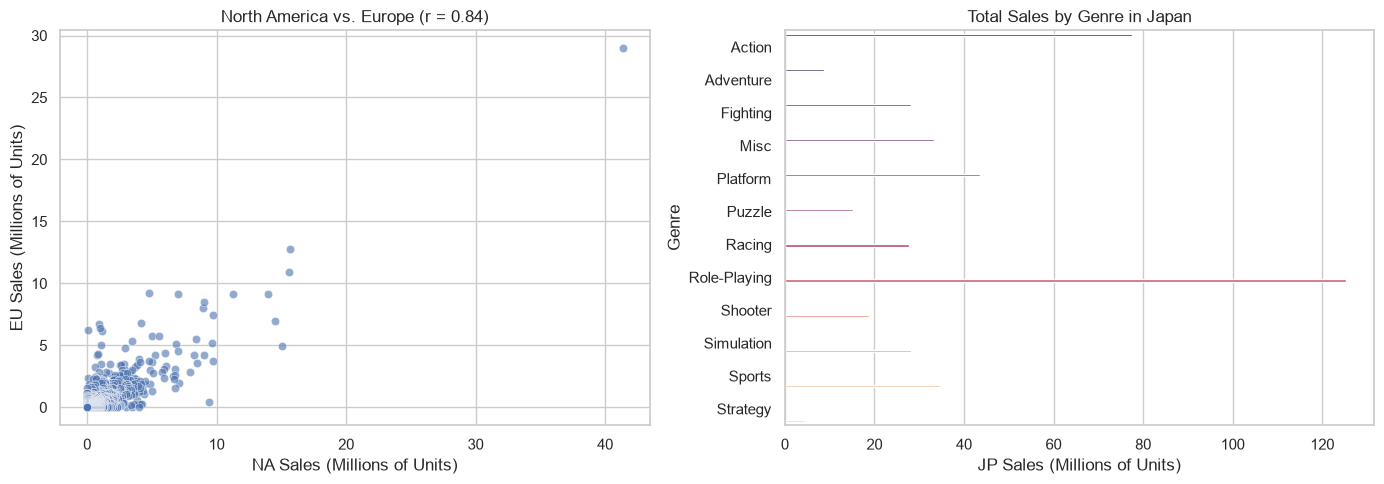

In [7]:
# Pearson correlation coefficient between NA and EU
corr_na_eu = df_clean['NA_Sales'].corr(df_clean['EU_Sales'])
print(f"Pearson Correlation Coefficient (NA vs EU): {corr_na_eu:.4f}")

# Plotting Western correlation and Japanese genre distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df_clean, x='NA_Sales', y='EU_Sales', ax=axes[0], alpha=0.6)
axes[0].set_title(f"North America vs. Europe (r = {corr_na_eu:.2f})")
axes[0].set_xlabel("NA Sales (Millions of Units)")
axes[0].set_ylabel("EU Sales (Millions of Units)")

jp_by_genre = df_clean.groupby('Genre', observed=False)['JP_Sales'].sum().sort_values(ascending=False)
sns.barplot(x=jp_by_genre.values, y=jp_by_genre.index, ax=axes[1], hue=jp_by_genre.index, palette="magma", legend=False)
axes[1].set_title("Total Sales by Genre in Japan")
axes[1].set_xlabel("JP Sales (Millions of Units)")

plt.tight_layout()
plt.show()

## 6. Bivariate & Regional Analysis

### 🔎 Interpretation: Regional Comparison
* **What we are observing:** Linear correlation between North American and European sales (left) alongside the genre breakdown in Japan (right).
* **What result we found:**
  1. High positive linear correlation (`r ≈ 0.84`) between NA and EU sales.
  2. In Japan, the **Role-Playing (RPG)** genre leads with ~125M units, outperforming Action (~78M) and Sports (~35M) by a substantial margin.
* **Business & Technical Meaning:** The Western market (NA + EU) acts homogeneously, allowing unified distribution strategies. Conversely, entering Japan requires portfolio adaptation heavily tailored to RPG titles.

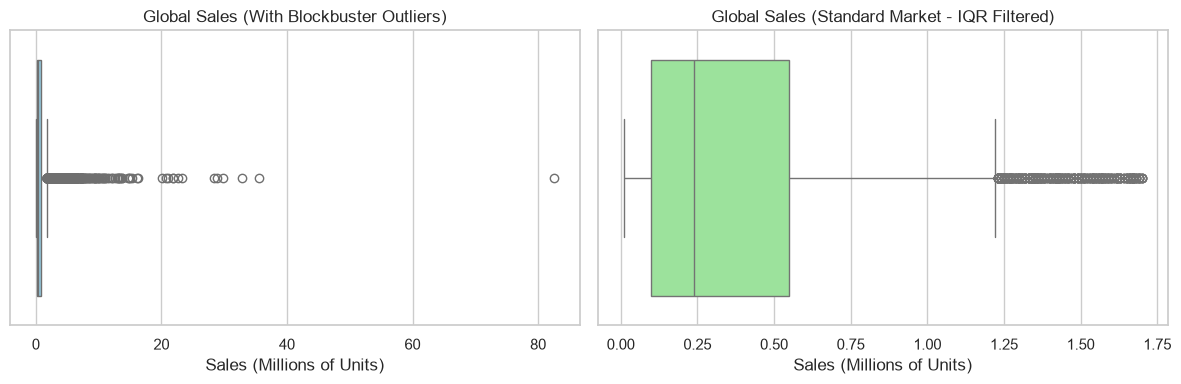

In [8]:
# Outlier removal using IQR
Q1 = df_clean['Global_Sales'].quantile(0.25)
Q3 = df_clean['Global_Sales'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
df_no_outliers = df_clean[df_clean['Global_Sales'] <= upper_bound]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_clean['Global_Sales'], ax=axes[0], color='skyblue')
axes[0].set_title("Global Sales (With Blockbuster Outliers)")
axes[0].set_xlabel("Sales (Millions of Units)")

sns.boxplot(x=df_no_outliers['Global_Sales'], ax=axes[1], color='lightgreen')
axes[1].set_title("Global Sales (Standard Market - IQR Filtered)")
axes[1].set_xlabel("Sales (Millions of Units)")

plt.tight_layout()
plt.show()

## 7. Outlier & Distribution Analysis

### 🔎 Interpretation: Outlier Analysis
* **What we are observing:** Distribution of global sales before and after filtering extreme outliers ($Q3 + 1.5 \times IQR$).
* **What result we found:** Titles above the IQR upper bound (~1.71M units) represent roughly **10% of the catalogue** yet inflate the mean (0.77M) to nearly **2.6× the median (0.29M)**; standard games operate in a much lower volume band.
* **Business & Technical Meaning:** Baseline financial projections for typical games must rely on the median or IQR-filtered data rather than the overall mean, which is heavily inflated by rare hits.

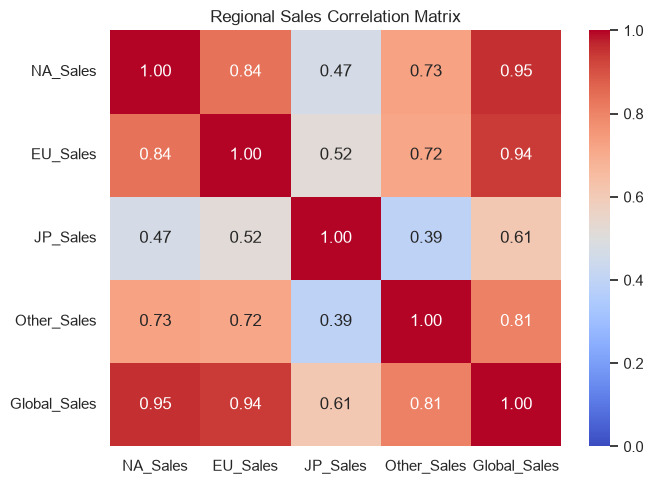

In [9]:
# Compute correlation matrix for numerical regional sales variables
sales_cols = [
    'NA_Sales',
    'EU_Sales',
    'JP_Sales',
    'Other_Sales',
    'Global_Sales',
]
corr_matrix = df_clean[sales_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=0, vmax=1)
plt.title('Regional Sales Correlation Matrix')
plt.tight_layout()
plt.show()

## 8. Regional Correlation Matrix

### 🔎 Interpretation: Sales Correlation Matrix
* **What we are observing:** Pearson correlation coefficients across all regional market combinations.
* **What result we found:** NA and EU sales display a strong positive correlation ($r \approx 0.84$), whereas JP sales show markedly lower correlation with the Western markets (0.47 with NA, 0.52 with EU).
* **Business & Technical Meaning:** Regional dynamics confirm that Western markets can be targeted with unified commercial campaigns, whereas Japan demands an independent regional strategy.

In [10]:
# Final sequential-execution check: engineered features from the pipeline are present
assert 'NA_EU_Share' in df_clean.columns
assert 'Sales_Category' in df_clean.columns

print(df_clean.columns.tolist())
print(df_clean.shape)
print(f"Nulls: {df_clean.isnull().sum().sum()}")
print(f"Duplicates: {df_clean.duplicated().sum()}")

['Platform', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Rating', 'Critic_Score_Class', 'NA_EU_Share', 'Sales_Category']
(7088, 12)
Nulls: 0
Duplicates: 0


## 9. Pipeline Verification

The unit tests in `test_pipeline.py` validate the pipeline contracts used throughout this notebook: null-publisher removal, duplicate removal, and the safe `NA_EU_Share` calculation.

In [11]:
!python -m pytest test_pipeline.py -v

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\lorig\AppData\Local\Python\pythoncore-3.14-64\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\lorig\Documents\IA-P1 BCN\Proyecto EDA - Exploratory Data Analysis
plugins: anyio-4.14.1, platformdirs-4.14.3
collecting ... collected 3 items

test_pipeline.py::test_clean_data_removes_null_publishers PASSED         [ 33%]
test_pipeline.py::test_engineer_features_na_eu_share PASSED              [ 66%]
test_pipeline.py::test_clean_data_removes_duplicates PASSED              [100%]

============================== warnings summary ===============================
..\..\..\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\anyio\pytest_plugin.py:14
  C:\Users\lorig\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\anyio\pytest_plugin.py:14: PytestRemovedIn10Warning: _pytest.python.CallSpec2 has been renamed to CallSpec.
  The Ca